In [232]:
import setuptools  # Ensures distutils is available
%pip install Cython
import pyximport
pyximport.install()
from scipy.integrate import trapezoid as trapz
import matplotlib.cm as cm
from datetime import datetime
import os
import shutil
import pandas as pd
#!/anaconda3/bin/python
from math import cos, sin, pi, sqrt
from numpy import (
    array, linspace, arange, loadtxt, vectorize, pi as npi, exp, zeros,
    empty, log, log2, finfo, true_divide, asarray, where, partition, isnan, nan,
    ones, argmax, argmin, set_printoptions, diagonal, round, inf,concatenate, sin, cos
    )
import imageio
from numpy.random import random
from scipy.integrate import trapezoid as trapz
from scipy.signal import correlate2d
from matplotlib import rcParams, rc, ticker, colors, cm
from matplotlib.style import use
from matplotlib.pyplot import subplots, close
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
from mpl_toolkits.axes_grid1 import make_axes_locatable
from os import getcwd
from datetime import datetime
import os
from matplotlib.patches import Rectangle
import matplotlib.font_manager as font_manager
import pyximport
import numpy as np
from matplotlib.ticker import ScalarFormatter
import matplotlib.colors as mcolors
from scipy.optimize import curve_fit, fsolve
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib
# Install setuptools to resolve the distutils issue
%pip install setuptools

import pyximport
pyximport.install()

from utilities import (
    calc_flux #, calc_learning_rate
    )
rc('font', **{'family': 'sans-serif', 'sans-serif': ['Helvetica']})
rc('text', usetex=True)


def infinite_eff(psi_0,psi_1,n0,n1,model):
    '''gets the psi_0/1 that is applied to model 1,3 
    (dont divide it for mod 2,4 before hand)'''
    
    if model=="model1":
        if abs(psi_0)>abs(psi_1):
            eff = - psi_1/psi_0
        else:
            eff = - psi_0/psi_1
    if model == "model2":
        if abs(n0*psi_0/8)>abs(n1*psi_1/3):
            eff = - (n1*psi_1/3)/(n0*psi_0/8)
        elif abs(n0*psi_0/8)==abs(n1*psi_1/3):
            eff =-1
        else:
            eff = - ((n0*psi_0/8)/(n1*psi_1/3))
    if model=="model3":
        X2 = (psi_0*((n1*psi_0/n0) + psi_1))
        X1 =(psi_1*(psi_0 + (n0*psi_1/n1)))
        if X2 != 0:
            if abs(psi_0/n0)>abs(psi_1/n1):
                eff = - X1/X2
            else:
                eff = - (X1/X2)**(-1)
        else:
            eff = 0
    if model == "model4":
        psi_0 = psi_0*n0/8
        psi_1 = psi_1*n1/3
        
        X2 = (psi_0*((n1*psi_0/n0) + psi_1))
        X1 =(psi_1*(psi_0 + (n0*psi_1/n1)))
        if X2 != 0:
            if abs(psi_0/n0)>abs(psi_1/n1):
                eff = - X1/X2
            else:
                eff = - (X1/X2)**(-1)
        else:
            eff = 0
            
        # eff = ["undefined" if x == -1 else x for x in eff]
    if model == "BFM" or model=="CS":
        eff = 0
    return eff

def set_params(model, n0,n1,f0,f1=-2.0,E0=2.0,E1=2.0):
    N = 100
    (model, n0,n1,f0,f1)
    
     # energy scale of Fo
    Ecouple = 20.0 # energy scale of coupling between Fo and F1


    psi_0 = f0
    psi_1 = f1
    psi_0_n = f0
    psi_1_n = f1
    
    m0 = 1.0
    m1 = 1.0
    beta = 1.0
    gamma = 1000.0
    phase = 0.0
    
    if model =="model4" or model =="model2":
        psi_0_n = n0*psi_0/8
        psi_1_n = n1*psi_1/3
    
    if model=="CS":
        psi_0_n = n0*psi_0/8
        psi_1_n = -0.0
        psi_1 = -0.0
        gamma = 1500.0
    if model=="BFM" and f1==-0.0:
        psi_0_n = n0*psi_0/8
        psi_1_n = psi_1
    

    return (
        E0, Ecouple, E1,  psi_0, psi_1, psi_0_n, psi_1_n, 
        n0, n1,
        m0, m1, phase,beta, gamma, model
        ) 

Python(96868) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Python(96869) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [233]:
l_title_s = 10
l_entry_s = 8
ticks_size = 9
fs = 10
ts = 11
ms = 3
off_text_size = 9


Finite-barrier tight-coupling predictions:
-------------------------------------------------------
beta mu_o =   8.0, n1 = 3  -->  n0* = 2
beta mu_o =   8.0, n1 = 5  -->  n0* = 2
beta mu_o =   8.0, n1 = 7  -->  n0* = 3
beta mu_o =  16.0, n1 = 3  -->  n0* = 2
beta mu_o =  16.0, n1 = 5  -->  n0* = 3
beta mu_o =  16.0, n1 = 7  -->  n0* = 4
beta mu_o =  32.0, n1 = 3  -->  n0* = 3
beta mu_o =  32.0, n1 = 5  -->  n0* = 4
beta mu_o =  32.0, n1 = 7  -->  n0* = 6
beta mu_o =  64.0, n1 = 3  -->  n0* = 3
beta mu_o =  64.0, n1 = 5  -->  n0* = 5
beta mu_o =  64.0, n1 = 7  -->  n0* = 7


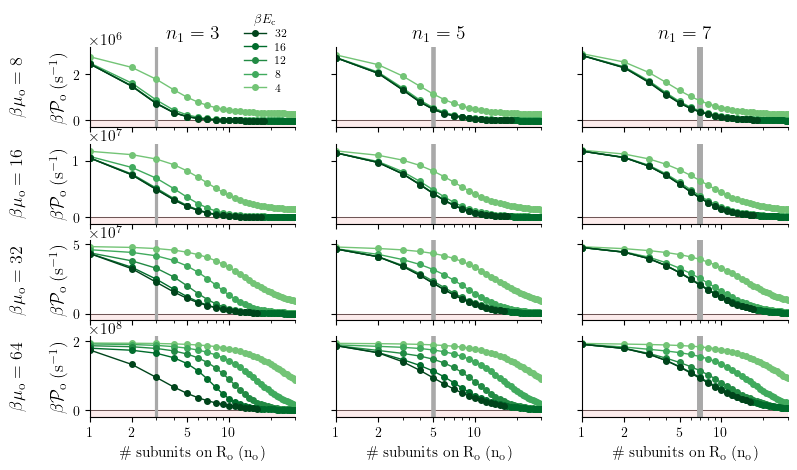

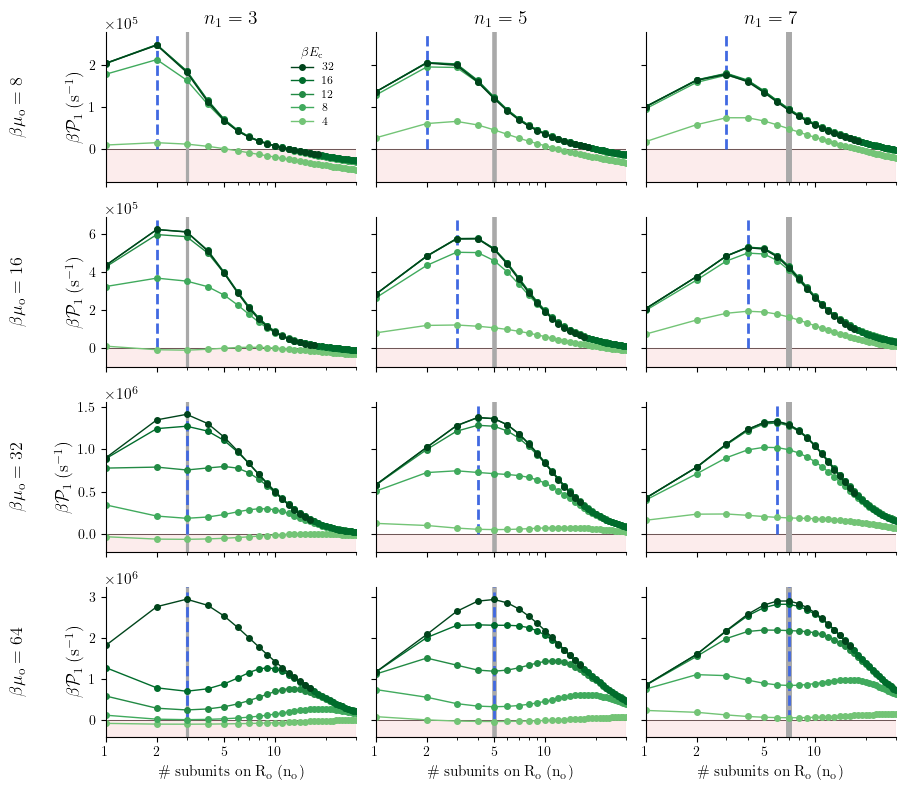

<Figure size 640x480 with 0 Axes>

In [234]:
def finite_barrier_tight_coupling_optimum(n0_array, n1, mu0, mu1=-2.0, E0=2.0, E1=2.0, beta=1.0, gamma=1000.0, N_int=4000):
    """Finite-barrier tight-coupling prediction, Eqs. (S58)-(S64)."""

    n0_array = np.asarray(n0_array, dtype=float)
    phi = np.linspace(0.0, 2.0*np.pi, N_int, endpoint=False)
    dphi = 2.0*np.pi/N_int

    def U(x):
        return -(E0 + E1)/2.0*np.cos(x)

    P1_array = []

    for n0 in n0_array:
        mu_eff = mu0/n0 + mu1/n1
        gamma_eff = gamma*(1.0/n0**2 + 1.0/n1**2)

        I_eff = np.empty_like(phi)
        for k, ph in enumerate(phi):
            exponent = beta*(U(ph) - U(ph - phi) - mu_eff*phi)
            I_eff[k] = beta*gamma_eff*np.sum(np.exp(exponent))*dphi

        denominator = np.sum(I_eff)*dphi/(2.0*np.pi)
        phi_dot = (1.0 - np.exp(-2.0*np.pi*beta*mu_eff))/denominator
        P1_array.append(-(mu1/n1)*phi_dot)

    P1_array = np.asarray(P1_array)
    n0_star = int(n0_array[np.nanargmax(P1_array)])

    return n0_star, P1_array


def plot_figure3(target_dir, model, n0_array, Ec_curve, n1_array, f0_array, drag=1000):
    timescale = 4.8e7
    W, M = len(f0_array), len(n1_array)

    # fig, ax = plt.subplots(W, M, figsize=(3*M, 1.2*W), sharey="row", sharex=True)
    fig, ax = plt.subplots(W, M, figsize=(3*M, 2*W), sharey="row", sharex=True)

    fig0, ax0 = plt.subplots(W, M, figsize=(3*M, 1.2*W), sharey="row", sharex=True)

    if W == 1 and M == 1:
        ax, ax0 = np.array([[ax]]), np.array([[ax0]])
    elif W == 1:
        ax, ax0 = ax[np.newaxis, :], ax0[np.newaxis, :]
    elif M == 1:
        ax, ax0 = ax[:, np.newaxis], ax0[:, np.newaxis]

    colors = cm.Greens(np.linspace(0.5, 1, len(Ec_curve)))[::-1]
    input_file_name = "/" + model + "_flux_power_efficiency_E0_{0}_E1_{1}_psi0_{2}_psi1_{3}_n0_{4}_n1_{5}_phase_{6}_outfile.dat"

    row_y_min, row_y_max = [np.inf]*W, [-np.inf]*W
    row_y_min0, row_y_max0 = [np.inf]*W, [-np.inf]*W

    # =========================================================================
    # NUMERICAL P1 AND P0
    # =========================================================================

    for wi, f0 in enumerate(f0_array):
        for mi, n1 in enumerate(n1_array):
            for i, Ec in enumerate(Ec_curve):
                n0_exists, P1_at_Ec, P0_at_Ec = [], [], []

                for n0 in n0_array:
                    n0n1_str = str(int(n0)) + "_" + str(int(n1))
                    target = target_dir if isinstance(target_dir, str) else target_dir[wi]
                    target_dir_temp = target + n0n1_str

                    [E0, __, E1, psi_0, psi_1, psi_0_n, psi_1_n, __, __, m0, m1, phase, beta, gamma, __] = set_params(model, n0, n1, f0, E0=2.0, E1=2.0)

                    fpath = target_dir_temp + input_file_name.format(E0, E1, psi_0, psi_1, n0, n1, phase)

                    if not os.path.exists(fpath):
                        continue

                    data = loadtxt(fpath, unpack=True, usecols=(0, 1, 2, 3, 4, 5, 6))
                    Ec_list, flux_X, flux_Y, power_X, power_Y, eff, eff_mod = data

                    if np.ndim(Ec_list) == 0:
                        Ec_list, power_X, power_Y = [Ec_list], [power_X], [power_Y]

                    for j in range(len(Ec_list)):
                        if np.isclose(Ec_list[j], Ec):
                            n0_exists.append(int(n0))
                            P1_at_Ec.append(-2*pi*power_Y[j])
                            P0_at_Ec.append(2*pi*power_X[j])

                if not n0_exists:
                    continue

                y1 = timescale*np.asarray(P1_at_Ec)
                y0 = timescale*np.asarray(P0_at_Ec)

                ax[wi, mi].plot(n0_exists, y1, marker="o", lw=1.0, markersize=4, label=fr"${int(Ec)}$", color=colors[i], zorder=-i)
                ax0[wi, mi].plot(n0_exists, y0, marker="o", lw=1.0, markersize=4, label=fr"${int(Ec)}$", color=colors[i], zorder=-i)

                row_y_min[wi] = min(row_y_min[wi], np.nanmin(y1))
                row_y_max[wi] = max(row_y_max[wi], np.nanmax(y1))
                row_y_min0[wi] = min(row_y_min0[wi], np.nanmin(y0))
                row_y_max0[wi] = max(row_y_max0[wi], np.nanmax(y0))

                # # numerical P1 maximum
                # valid = np.isfinite(y1) & (y1 > 0)
                # if np.any(valid):
                #     inds = np.flatnonzero(valid)
                #     idx = inds[np.argmax(y1[valid])]
                #     ax[wi, mi].plot(n0_exists[idx], y1[idx], marker="o", markersize=5, color=colors[i], markeredgewidth=0, linestyle="none", zorder=100)

                # # numerical P0 maximum
                # valid0 = np.isfinite(y0) & (y0 > 0)
                # if np.any(valid0):
                #     inds0 = np.flatnonzero(valid0)
                #     idx0 = inds0[np.argmax(y0[valid0])]
                #     ax0[wi, mi].plot(n0_exists[idx0], y0[idx0], marker="o", markersize=5, color=colors[i], markeredgewidth=0, linestyle="none", zorder=100)

            # symmetry match
            ax[wi, mi].axvline(n1, color="darkgray", linestyle="solid", linewidth=mi + 2.3, zorder=-50)
            ax0[wi, mi].axvline(n1, color="darkgray", linestyle="solid", linewidth=mi + 2.3, zorder=-50)

            # formatting
            for a, ylabel in [(ax[wi, mi], r"$\beta \mathcal{P}_{1} \ (\rm{s}^{-1})$"), (ax0[wi, mi], r"$\beta \mathcal{P}_{\rm o} \ (\rm{s}^{-1})$")]:
                a.axhline(0.0, color="black", lw=0.5, zorder=-100)
                a.ticklabel_format(style="sci", axis="y", scilimits=(0, 0))
                a.yaxis.offsetText.set_fontsize(11)
                a.set_xscale("log")
                a.set_xlim(1, 30)
                a.set_xticks([1, 2, 5, 10])
                a.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
                a.spines["right"].set_visible(False)
                a.spines["top"].set_visible(False)
                a.tick_params(labelsize=10)

                if wi == 0:
                    a.set_title(fr"$n_1 = {int(n1)}$", fontsize=14)

                if wi == W-1:
                    a.set_xlabel(r"$\# \ \mathrm{subunits \ on} \ \rm{R}_{\rm o} \ (n_{\rm o})$", fontsize=11)

                if mi == 0:
                    a.set_ylabel(ylabel, fontsize=13)
                    a.annotate(fr"$\beta\mu_{{\rm o}} = {int(f0)}$", xy=(-0.35, 0.5), xycoords="axes fraction", fontsize=13, ha="center", va="center", rotation=90)

                if wi == 0 and mi == 0:
                    a.legend(prop={"size": 8}, title=r"$\beta E_{\rm c}$", title_fontsize=9, frameon=False, labelspacing=0.3, loc="best", bbox_to_anchor=(0.7, 0.3))

    # =========================================================================
    # ROW-WISE Y LIMITS + NEGATIVE-POWER SHADING
    # =========================================================================

    row_ylims = {}

    for wi in range(W):
        if row_y_min[wi] < np.inf:
            yr = row_y_max[wi] - row_y_min[wi]
            y_lo, y_hi = row_y_min[wi] - 0.1*yr, row_y_max[wi] + 0.1*yr
            row_ylims[wi] = (y_lo, y_hi)

            for mi in range(M):
                ax[wi, mi].set_ylim(y_lo, y_hi)
                if y_lo < 0:
                    ax[wi, mi].axhspan(y_lo, 0, color="lightcoral", alpha=0.15, zorder=-100)

        if row_y_min0[wi] < np.inf:
            yr0 = row_y_max0[wi] - row_y_min0[wi]
            y_lo0, y_hi0 = row_y_min0[wi] - 0.1*yr0, row_y_max0[wi] + 0.1*yr0

            for mi in range(M):
                ax0[wi, mi].set_ylim(y_lo0, y_hi0)
                if y_lo0 < 0:
                    ax0[wi, mi].axhspan(y_lo0, 0, color="lightcoral", alpha=0.15, zorder=-100)

    # =========================================================================
    # THEORETICAL n0* — BLUE DASHED LINE ON P1
    # =========================================================================

    print("\nFinite-barrier tight-coupling predictions:")
    print("-"*55)

    theory_records = []

    for wi, f0 in enumerate(f0_array):
        for mi, n1 in enumerate(n1_array):
            n0_star, P1_theory = finite_barrier_tight_coupling_optimum(n0_array, n1, f0, mu1=-2.0, E0=2.0, E1=2.0, beta=1.0, gamma=drag)

            theory_records.append({"f0": f0, "n1": int(n1), "n0_star": n0_star})
            print(f"beta mu_o = {f0:5.1f}, n1 = {int(n1)}  -->  n0* = {n0_star}")

            if wi in row_ylims:
                y_lo, y_hi = row_ylims[wi]
                ymin_frac = np.clip((0.0-y_lo)/(y_hi-y_lo), 0.0, 1.0)
                ax[wi, mi].axvline(n0_star, ymin=ymin_frac, ymax=1.0, color="royalblue", linestyle="--", linewidth=2, zorder=-40)

    df_theory = pd.DataFrame(theory_records)
    df_theory.to_csv("/Users/sara/Desktop/research/BFM_paper/tight_coupling_n0_star_model3.csv", index=False)

    # =========================================================================
    # SAVE BOTH FIGURES
    # =========================================================================

    fig.tight_layout()
    fig.savefig("/Users/sara/Desktop/research/BFM_paper/P1_vs_n0_grid_model_model3.pdf", bbox_inches="tight")
    plt.figure(fig.number)
    plt.show()

    fig0.tight_layout()
    fig0.savefig("/Users/sara/Desktop/research/BFM_paper/P0_vs_n0_grid_model_model3.pdf", bbox_inches="tight")
    plt.figure(fig0.number)
    plt.show()

    return df_theory


# =============================================================================
# CALL
# =============================================================================

n0_array_n0_change = [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 19.0, 20.0, 21.0, 22.0, 23.0, 24.0, 25.0, 26.0, 27.0, 28.0, 29.0, 30.0]
Ec_curve_n0_change = [32.0, 16.0, 14.0, 12.0, 10.0, 8.0, 6.0, 4.0]
Ec_curve_n0_change = [32.0, 16.0, 12.0, 8.0, 4.0]



target_dir = "/Users/sara/Desktop/Figs_paper_2/model3/pfe/"

df_theory = plot_figure3(target_dir=target_dir, model="model3", n0_array=n0_array_n0_change, Ec_curve=Ec_curve_n0_change, n1_array=[3.0, 5.0, 7.0], f0_array=[8.0,16.0,32.0,64.0], drag=1000)


Saved: /Users/sara/Desktop/research/BFM_paper/Barrierless_symmetry_match_power_advantage.pdf


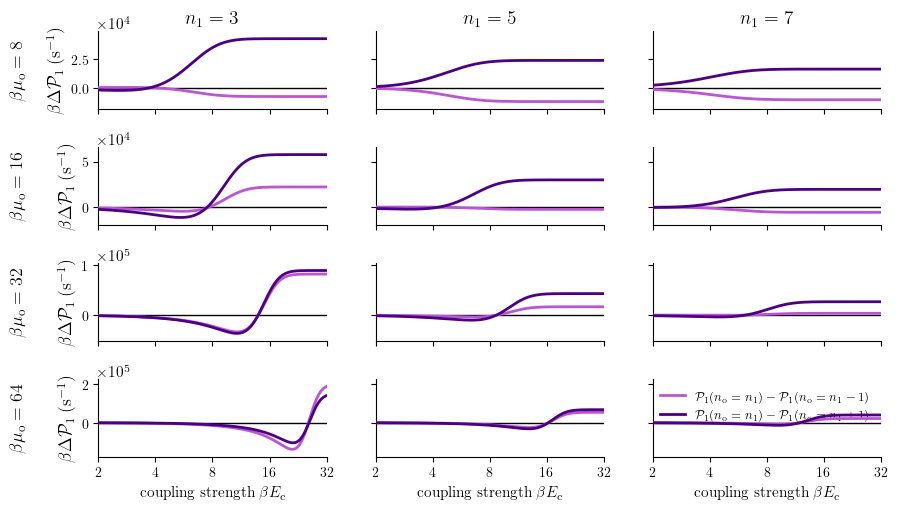

In [235]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from scipy.integrate import quad
from scipy.special import i0e


# ================================================================
# EXACT BARRIERLESS RELATIVE VELOCITY
# ================================================================

def relative_velocity_exact(
    n0, n1, mu0, mu1, Ec,
    beta=1.0,
    gamma=1000.0
):
    n_squared = n0**2 + n1**2

    mu_eff = 0.5 * (n0 * mu0 - n1 * mu1)

    f = 4.0 * mu_eff / n_squared

    def integrand(y):
        z = beta * Ec * np.sin(y)

        return i0e(z) * np.exp(
            z - beta * f * y
        )

    integral, _ = quad(
        integrand,
        0.0,
        np.pi,
        epsabs=1e-10,
        epsrel=1e-10,
        limit=300
    )

    numerator = -np.expm1(
        -np.pi * beta * f
    )

    return (
        n_squared * numerator
        / (4.0 * beta * gamma * integral)
    )


# ================================================================
# EXACT BARRIERLESS OUTPUT POWER
# ================================================================

def output_power_exact(
    n0, n1, mu0, mu1, Ec,
    beta=1.0,
    gamma=1000.0
):
    n_squared = n0**2 + n1**2

    delta_velocity = relative_velocity_exact(
        n0, n1, mu0, mu1, Ec, beta, gamma
    )

    bar_velocity = (
        n1 * mu0 + n0 * mu1
    ) / (2.0 * gamma)

    theta1_velocity = (
        2.0 * (
            n0 * bar_velocity
            - n1 * delta_velocity
        ) / n_squared
    )

    return -mu1 * theta1_velocity


# ================================================================
# CALCULATE POWER DIFFERENCES
# ================================================================

def calculate_power_differences(
    n1,
    mu0,
    Ec_array,
    mu1=-2.0,
    beta=1.0,
    gamma=1000.0,
    timescale=4.8e7
):

    P_left = np.array([
        output_power_exact(
            n1 - 1, n1, mu0, mu1, Ec,
            beta, gamma
        )
        for Ec in Ec_array
    ])

    P_match = np.array([
        output_power_exact(
            n1, n1, mu0, mu1, Ec,
            beta, gamma
        )
        for Ec in Ec_array
    ])

    P_right = np.array([
        output_power_exact(
            n1 + 1, n1, mu0, mu1, Ec,
            beta, gamma
        )
        for Ec in Ec_array
    ])

    difference_left = (
        timescale * beta * (P_match - P_left)
    )

    difference_right = (
        timescale * beta * (P_match - P_right)
    )

    return difference_left, difference_right


# ================================================================
# MULTI-PANEL FIGURE
# ================================================================

def plot_symmetry_match_power_advantage(
    n1_array,
    mu0_array,
    Ec_array,
    mu1=-2.0,
    beta=1.0,
    gamma=1000.0,
    timescale=4.8e7,
    save_dir=None
):

    W = len(mu0_array)
    M = len(n1_array)

    fig, axes = plt.subplots(
        W,
        M,
        figsize=(3 * M, 1.3 * W),
        sharex=True,
        sharey="row",
        squeeze=False
    )

    row_limits = []

    xmin = beta * Ec_array[0]
    xmax = beta * Ec_array[-1]

    # ============================================================
    # CALCULATE AND PLOT
    # ============================================================

    for wi, mu0 in enumerate(mu0_array):

        row_min = np.inf
        row_max = -np.inf

        for mi, n1 in enumerate(n1_array):

            ax = axes[wi, mi]

            diff_left, diff_right = calculate_power_differences(
                n1=n1,
                mu0=mu0,
                Ec_array=Ec_array,
                mu1=mu1,
                beta=beta,
                gamma=gamma,
                timescale=timescale
            )

            # ====================================================
            # POWER DIFFERENCE CURVES
            # ====================================================

            ax.plot(
                beta * Ec_array,
                diff_left,
                color="mediumorchid",
                lw=2,
                zorder=10
            )

            ax.plot(
                beta * Ec_array,
                diff_right,
                color="indigo",
                lw=2,
                zorder=10
            )

            # Horizontal zero reference line
            ax.axhline(
                0,
                color="black",
                lw=1,
                zorder=3
            )

            # ====================================================
            # TRACK ROW LIMITS
            # ====================================================

            row_min = min(
                row_min,
                np.nanmin(diff_left),
                np.nanmin(diff_right)
            )

            row_max = max(
                row_max,
                np.nanmax(diff_left),
                np.nanmax(diff_right)
            )

            # ====================================================
            # AXIS FORMATTING
            # ====================================================

            ax.set_xscale("log")
            ax.set_xlim(xmin, xmax)

            ax.xaxis.set_major_locator(
                ticker.FixedLocator([2, 4, 8, 16, 32])
            )

            ax.xaxis.set_major_formatter(
                ticker.ScalarFormatter()
            )

            ax.xaxis.set_minor_locator(
                ticker.NullLocator()
            )

            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)

            ax.tick_params(labelsize=10)

            if wi == 0:
                ax.set_title(
                    rf"$n_1={n1}$",
                    fontsize=14
                )

            if wi == W - 1:
                ax.set_xlabel(
                    r"$\mathrm{coupling\ strength}\ "
                    r"\beta E_{\rm c}$",
                    fontsize=11
                )

            if mi == 0:

                ax.set_ylabel(
                    r"$\beta\Delta\mathcal{P}_1\;(\mathrm{s}^{-1})$",
                    fontsize=13
                )

                ax.annotate(
                    rf"$\beta\mu_{{\rm o}}={beta*mu0:g}$",
                    xy=(-0.35, 0.5),
                    xycoords="axes fraction",
                    fontsize=13,
                    ha="center",
                    va="center",
                    rotation=90
                )

        row_limits.append(
            (row_min, row_max)
        )

    # ================================================================
    # ROW-WISE Y LIMITS
    # ================================================================

    for wi, (ymin, ymax) in enumerate(row_limits):

        yrange = ymax - ymin

        padding = (
            0.12 * yrange
            if yrange > 0
            else 0.001
        )

        lower = ymin - padding
        upper = ymax + padding

        for mi in range(M):

            ax = axes[wi, mi]

            ax.set_ylim(lower, upper)

            ax.ticklabel_format(
                style="sci",
                axis="y",
                scilimits=(0, 0)
            )

            ax.yaxis.offsetText.set_fontsize(11)

    # ================================================================
    # LEGEND
    # ================================================================

    handles = [
        plt.Line2D(
            [0], [0],
            color="mediumorchid",
            lw=2
        ),
        plt.Line2D(
            [0], [0],
            color="indigo",
            lw=2
        )
    ]

    labels = [
        r"$\mathcal{P}_1(n_{\rm o}=n_1)"
        r"-\mathcal{P}_1(n_{\rm o}=n_1-1)$",

        r"$\mathcal{P}_1(n_{\rm o}=n_1)"
        r"-\mathcal{P}_1(n_{\rm o}=n_1+1)$"
    ]

    axes[-1, -1].legend(
        handles,
        labels,
        loc="upper right",
        fontsize=9,
        frameon=False,
        ncol=1
    )

    fig.tight_layout(
        rect=[0, 0, 1, 1],
        w_pad=1.5,
        h_pad=1.3
    )

    # ================================================================
    # SAVE FIGURE
    # ================================================================

    if save_dir is not None:

        os.makedirs(
            save_dir,
            exist_ok=True
        )

        filename = os.path.join(
            save_dir,
            "Barrierless_symmetry_match_power_advantage.pdf"
        )

        fig.savefig(
            filename,
            bbox_inches="tight",
            dpi=300
        )

        print(f"\nSaved: {filename}")

    plt.show()


# ================================================================
# PARAMETERS
# ================================================================

beta = 1.0
gamma = 1000.0
mu1 = -2.0

timescale = 4.8e7

n1_array = [3, 5, 7]

mu0_array = [
    8.0,
    16.0,
    32.0,
    64.0
]

Ec_array = np.geomspace(
    2.0 / beta,
    32.0 / beta,
    250
)

save_dir = "/Users/sara/Desktop/research/BFM_paper/"


# ================================================================
# RUN
# ================================================================

plot_symmetry_match_power_advantage(
    n1_array=n1_array,
    mu0_array=mu0_array,
    Ec_array=Ec_array,
    mu1=mu1,
    beta=beta,
    gamma=gamma,
    timescale=timescale,
    save_dir=save_dir
)

# phase diagram mod 3:  extrema anywhere


n1 = 3
Interior global maxima: 65
Interior local minima: 64
Excluded boundary/neither cases: 3
Missing: 4

n1 = 5
Interior global maxima: 98
Interior local minima: 35
Excluded boundary/neither cases: 0
Missing: 3

n1 = 7
Interior global maxima: 113
Interior local minima: 19
Excluded boundary/neither cases: 0
Missing: 4


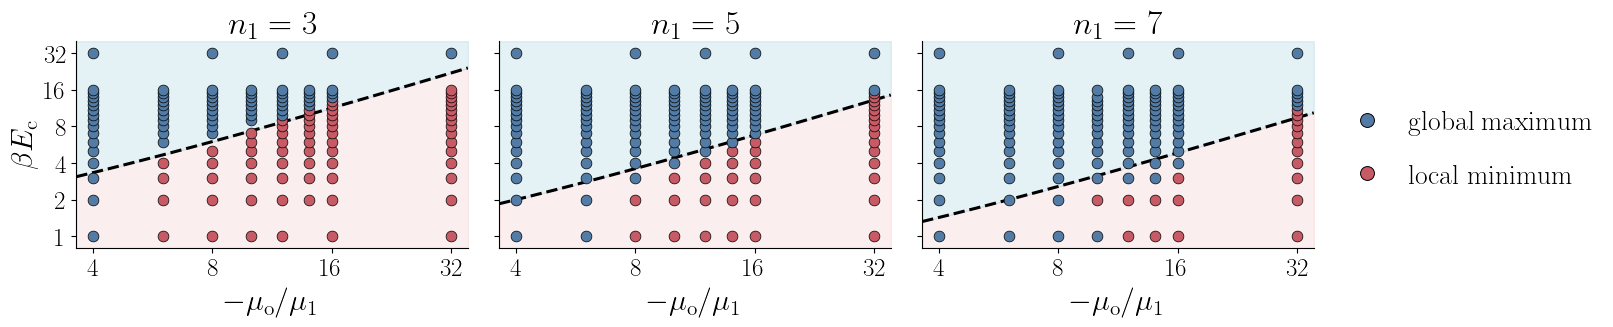

In [236]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import NullLocator, FixedLocator, FixedFormatter
from matplotlib.lines import Line2D


def plot_dip_peak_phase_diagram(
    target_dir,
    model,
    n1_array,
    f0_array,
    Ec_array,
    mu1=-2.0,
    beta=1.0,
    save_dir=None,
    target_dir_1000=None
):

    timescale = 4.8e7

    input_file_name = (
        "/{0}_flux_power_efficiency_E0_{1}_E1_{2}_psi0_{3}"
        "_psi1_{4}_n0_{5}_n1_{6}_phase_{7}_outfile.dat"
    )

    if save_dir is None:
        save_dir = target_dir

    os.makedirs(save_dir, exist_ok=True)

    Ec_values = np.sort(
        np.unique(np.asarray(Ec_array, dtype=float))
    )

    f0_array = np.asarray(f0_array, dtype=float)
    r_array = -f0_array / mu1

    if np.any(r_array <= 0):
        raise ValueError(
            "Driving ratios must be positive for a logarithmic x-axis."
        )

    if np.any(Ec_values <= 0):
        raise ValueError(
            "Coupling values must be positive for a logarithmic y-axis."
        )

    # ============================================================
    # CLASSIFICATION
    # ============================================================
    #
    # -1 : Interior local minimum (red)
    #  0 : Neither / boundary extremum (not plotted)
    #  1 : Interior global maximum (blue)
    #
    # Boundaries n0=1 and n0=30 are excluded as extrema.
    #
    # Priority:
    # 1. Local minimum
    # 2. Global maximum
    # 3. Neither
    #
    # ============================================================

    colors = {
        -1: "#C65A65",
         1: "#527CA5"
    }

    results = {}
    locations = {}

    n0_min = 1
    n0_max = 30

    y_min = 0.8
    y_max = 40.0

    # ============================================================
    # CREATE FIGURE
    # ============================================================

    fig, axes = plt.subplots(
        1,
        len(n1_array),
        figsize=(5 * len(n1_array), 3),
        sharex=True,
        sharey=True
    )

    if len(n1_array) == 1:
        axes = [axes]

    fig.subplots_adjust(
        left=0.075,
        right=0.9,
        bottom=0.19,
        top=0.88,
        wspace=0.08
    )

    # ============================================================
    # LOOP OVER DOWNSTREAM SYMMETRIES
    # ============================================================

    for ni, n1 in enumerate(n1_array):

        ax = axes[ni]
        n1_int = int(n1)

        phase = np.full(
            (len(Ec_values), len(f0_array)),
            np.nan
        )

        location = np.full(
            (len(Ec_values), len(f0_array)),
            np.nan
        )

        # ========================================================
        # LOAD NUMERICAL P1 OVER FULL n0 RANGE
        # ========================================================

        for j, f0 in enumerate(f0_array):

            powers = {}

            if np.any(
                np.isclose(f0, [12.0, 20.0, 28.0, 36.0])
            ):
                current_target_dir = target_dir_1000
            else:
                current_target_dir = target_dir

            if current_target_dir is None:
                raise ValueError(
                    f"No PFE directory specified for psi0={f0}"
                )

            for n0 in range(n0_min, n0_max + 1):

                [
                    E0,
                    __,
                    E1,
                    psi_0,
                    psi_1,
                    psi_0_n,
                    psi_1_n,
                    __,
                    __,
                    m0,
                    m1,
                    phase0,
                    beta0,
                    gamma,
                    __
                ] = set_params(
                    model,
                    n0,
                    n1,
                    f0,
                    E0=2.0,
                    E1=2.0
                )

                target_dir_temp = os.path.join(
                    current_target_dir,
                    f"{int(n0)}_{int(n1)}"
                )

                fpath = (
                    target_dir_temp
                    + input_file_name.format(
                        model,
                        E0,
                        E1,
                        psi_0,
                        psi_1,
                        float(n0),
                        n1,
                        phase0
                    )
                )

                if not os.path.exists(fpath):
                    print(f"Missing file: {fpath}")
                    continue

                try:

                    data = np.loadtxt(
                        fpath,
                        unpack=True,
                        usecols=(0, 4),
                        ndmin=2
                    )

                    Ec_list, power_Y = data

                    powers[n0] = {
                        float(Ec): -2 * np.pi * P1 * timescale
                        for Ec, P1 in zip(Ec_list, power_Y)
                    }

                except (OSError, ValueError) as exc:

                    print(
                        f"Could not read {fpath}: {exc}"
                    )

            # ====================================================
            # CLASSIFY EACH POWER CURVE
            # ====================================================

            for i, Ec in enumerate(Ec_values):

                P = {}

                for n0 in range(n0_min, n0_max + 1):

                    if n0 not in powers:
                        continue

                    matching = [
                        value
                        for Ec_data, value in powers[n0].items()
                        if np.isclose(Ec_data, Ec)
                    ]

                    if matching and np.isfinite(matching[0]):
                        P[n0] = matching[0]

                # Require the complete curve.
                if not all(
                    n0 in P
                    for n0 in range(n0_min, n0_max + 1)
                ):
                    continue

                # ================================================
                # STEP 1: SEARCH FOR INTERIOR LOCAL MINIMA
                # ================================================

                local_minima = [
                    n0
                    for n0 in range(n0_min + 1, n0_max)
                    if (
                        P[n0] < P[n0 - 1]
                        and P[n0] < P[n0 + 1]
                    )
                ]

                if local_minima:

                    # If multiple local minima exist,
                    # select the deepest one.
                    selected_minimum = min(
                        local_minima,
                        key=P.get
                    )

                    phase[i, j] = -1
                    location[i, j] = selected_minimum

                    # Minimum takes priority.
                    continue

                # ================================================
                # STEP 2: SEARCH FOR INTERIOR GLOBAL MAXIMUM
                # ================================================

                global_maximum = max(
                    P,
                    key=P.get
                )

                if n0_min < global_maximum < n0_max:

                    phase[i, j] = 1
                    location[i, j] = global_maximum

                else:

                    # Boundary maximum or neither.
                    # Do not plot a marker.
                    phase[i, j] = 0

        # ========================================================
        # ANALYTICAL LOCKING BOUNDARY
        # ========================================================

        x_min = r_array.min() / 1.1
        x_max = r_array.max() * 1.1

        r_theory = np.geomspace(
            x_min,
            x_max,
            1000
        )

        Ec_lock = (
            beta * abs(mu1) * (r_theory + 1) / n1
        )

        # ========================================================
        # THEORETICAL REGION SHADING
        # ========================================================

        ax.fill_between(
            r_theory,
            y_min,
            np.clip(Ec_lock, y_min, y_max),
            color="#F4C7C7",
            alpha=0.30,
            zorder=0
        )

        ax.fill_between(
            r_theory,
            np.clip(Ec_lock, y_min, y_max),
            y_max,
            color="#A6D1E1",
            alpha=0.30,
            zorder=0
        )

        ax.plot(
            r_theory,
            Ec_lock,
            color="black",
            linestyle="--",
            linewidth=2.2,
            zorder=3
        )

        # ========================================================
        # SCATTER PLOT — RED AND BLUE ONLY
        # ========================================================

        for classification in [-1, 1]:

            rows, cols = np.where(
                phase == classification
            )

            if len(rows) == 0:
                continue

            ax.scatter(
                r_array[cols],
                Ec_values[rows],
                s=60,
                color=colors[classification],
                edgecolor="black",
                linewidth=0.5,
                marker="o",
                zorder=5
            )

        # ========================================================
        # FORMATTING
        # ========================================================

        ax.set_xscale("log")
        ax.set_yscale("log")

        ax.set_xlabel(
            r"$-\mu_{\rm o}/\mu_1$",
            fontsize=22
        )

        ax.set_title(
            fr"$n_1={n1_int}$",
            fontsize=24
        )

        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, y_max)

        ax.set_xticks([4, 8, 16, 32])

        ax.set_xticklabels(
            [
                r"$4$",
                r"$8$",
                r"$16$",
                r"$32$"
            ],
            fontsize=20
        )

        ax.xaxis.set_minor_locator(
            NullLocator()
        )

        Ec_ticks = [1, 2, 4, 8, 16, 32]

        ax.yaxis.set_major_locator(
            FixedLocator(Ec_ticks)
        )

        ax.yaxis.set_major_formatter(
            FixedFormatter(
                [rf"${x}$" for x in Ec_ticks]
            )
        )

        ax.yaxis.set_minor_locator(
            NullLocator()
        )

        ax.tick_params(
            axis="both",
            which="major",
            labelsize=18
        )

        ax.spines["right"].set_visible(False)
        ax.spines["top"].set_visible(False)

        if ni == 0:

            ax.set_ylabel(
                r"$\beta E_{\rm c}$",
                fontsize=22
            )

        # ========================================================
        # STORE RESULTS
        # ========================================================

        results[n1_int] = phase
        locations[n1_int] = location

        # ========================================================
        # PRINT CLASSIFICATION SUMMARY
        # ========================================================

        print(f"\nn1 = {n1_int}")

        print(
            f"Interior global maxima: "
            f"{np.sum(phase == 1)}"
        )

        print(
            f"Interior local minima: "
            f"{np.sum(phase == -1)}"
        )

        print(
            f"Excluded boundary/neither cases: "
            f"{np.sum(phase == 0)}"
        )

        print(
            f"Missing: "
            f"{np.sum(np.isnan(phase))}"
        )

    # ============================================================
    # TWO-CATEGORY LEGEND
    # ============================================================

    legend_handles = [
        Line2D(
                    [0],
                    [0],
                    marker="o",
                    linestyle="none",
                    markerfacecolor=colors[1],
                    markeredgecolor="black",
                    markeredgewidth=0.7,
                    markersize=10,
                    label=r"$\mathrm{global \ maximum}$"
                ),

        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="none",
            markerfacecolor=colors[-1],
            markeredgecolor="black",
            markeredgewidth=0.7,
            markersize=10,
            label=r"$\mathrm{local \ minimum}$"
        )

        
    ]

    fig.legend(
        handles=legend_handles,
        loc="center left",
        bbox_to_anchor=(0.9, 0.52),
        frameon=False,
        fontsize=20,
        handletextpad=0.5,
        labelspacing=1.0
    )

    # ============================================================
    # SAVE COMBINED FIGURE
    # ============================================================

    filename = os.path.join(
        save_dir,
        "dip_peak_phase_diagram_combined_anywhere.pdf"
    )

    fig.savefig(
        filename,
        bbox_inches="tight"
    )

    plt.show()

    return results, locations


# ================================================================
# CALL
# ================================================================

target_dir = (
    "/Users/sara/Desktop/Figs_paper_2/model3/pfe_2000/"
)

target_dir_1000 = (
    "/Users/sara/Desktop/Figs_paper_2/model3/pfe/"
)

phase_results, extremum_locations = plot_dip_peak_phase_diagram(
    target_dir=target_dir,
    target_dir_1000=target_dir_1000,
    model="model3",
    n1_array=[3.0, 5.0, 7.0],
    f0_array=[
        8.0,
        12.0,
        16.0,
        20.0,
        24.0,
        28.0,
        32.0,
        64.0
    ],
    Ec_array=np.append(
        np.arange(1, 17),
        32
    ),
    mu1=-2.0,
    save_dir="/Users/sara/Desktop/research/BFM_paper/"
)

## Slippage model 3


VERIFYING UNCOUPLED SINGLE-ROTOR FLUX
n= 3, mu=   8.0, J_exact=+1.273239545e-03, J_expected=+1.273239545e-03, relative error=3.406e-16
n= 3, mu=  16.0, J_exact=+2.546479089e-03, J_expected=+2.546479089e-03, relative error=3.406e-16
n= 5, mu=  32.0, J_exact=+5.092958179e-03, J_expected=+5.092958179e-03, relative error=3.406e-16
n= 7, mu=  64.0, J_exact=+1.018591636e-02, J_expected=+1.018591636e-02, relative error=3.406e-16
n= 3, mu=  -2.0, J_exact=-3.183098862e-04, J_expected=-3.183098862e-04, relative error=5.109e-16
n= 5, mu=  -2.0, J_exact=-3.183098862e-04, J_expected=-3.183098862e-04, relative error=5.109e-16
n= 7, mu=  -2.0, J_exact=-3.183098862e-04, J_expected=-3.183098862e-04, relative error=5.109e-16

All barrierless flux checks passed.

NORMALIZED MODEL 3 SLIPPAGE AT SYMMETRY MATCH

n0=n1= 3, beta mu0=  8.0
  J0(0)        = +1.194376760e-03
  J1(0)        = -2.257507903e-04
  J_slip(0)    = +4.260382652e-03
  beta Ec_lock = 3.333333
  max ratio    = 0.943156

n0=n1= 3, beta mu

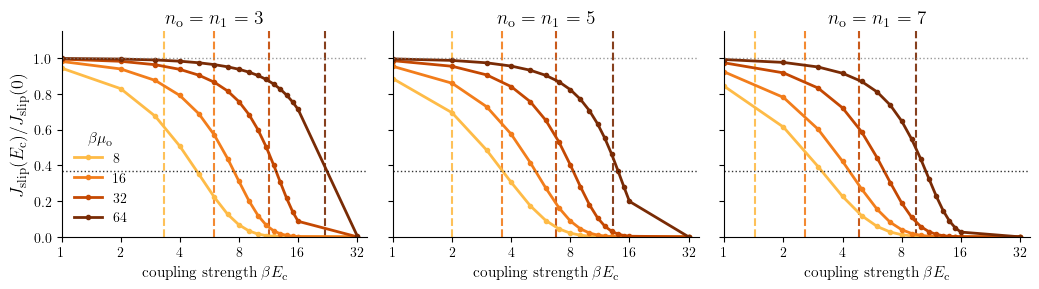

In [237]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from scipy.integrate import quad
from scipy.special import i0e


# ================================================================
# PARAMETERS
# ================================================================

model = "model3"

target_dir = "/Users/sara/Desktop/Figs_paper_2/model3/pfe_2000/"
save_dir = "/Users/sara/Desktop/research/BFM_paper/"

beta = 1.0
gamma = 1000.0

mu1 = -2.0

E0 = 2.0
E1 = 2.0

n1_array = [3.0, 5.0, 7.0]

mu0_array = [8.0, 16.0, 32.0, 64.0]

Ec_array = [
    1.0,
    2.0,
    3.0,
    4.0,
    5.0,
    6.0,
    7.0,
    8.0,
    9.0,
    10.0,
    11.0,
    12.0,
    13.0,
    14.0,
    15.0,
    16.0,
    20.0,
    24.0,
    28.0,
    32.0
]


# ================================================================
# DETERMINISTIC BARRIERLESS LOCKING THRESHOLD
# ================================================================

def locking_threshold(n0, n1, mu0, mu1, beta=1.0):
    """
    Deterministic barrierless locking threshold.

    Returns beta*Ec_lock.
    """

    Ec_lock = (
        2.0 * (n0 * mu0 - n1 * mu1)
        / (n0**2 + n1**2)
    )

    return beta * Ec_lock


# ================================================================
# EXACT UNCOUPLED SINGLE-ROTOR FLUX
# ================================================================

def uncoupled_rotor_flux(
    n,
    mu,
    E,
    beta=1.0,
    gamma=1000.0
):
    """
    Exact stationary revolution flux for one overdamped rotor:

        V(theta) = -(E/2) cos(n*theta)

    with constant driving mu.

    Returns
    -------
    J : float
        Mean revolutions per simulation-time unit:

            J = <theta_dot> / (2*pi)

    The expression is evaluated using a stable
    one-dimensional integral involving I0.
    """

    if mu == 0.0:
        return 0.0

    # Reflection symmetry of the cosine potential:
    # J(-mu) = -J(mu)

    sign = np.sign(mu)
    mu_abs = abs(mu)

    def integrand(y):

        z = beta * E * np.sin(0.5 * n * y)

        # i0e(z) = exp(-abs(z))*I0(z)
        #
        # Therefore:
        # I0(z) = i0e(z)*exp(abs(z))

        return (
            i0e(z)
            * np.exp(abs(z) - beta * mu_abs * y)
        )

    integral, error = quad(
        integrand,
        0.0,
        2.0 * np.pi,
        epsabs=1e-11,
        epsrel=1e-11,
        limit=500
    )

    numerator = -np.expm1(
        -2.0 * np.pi * beta * mu_abs
    )

    # Correct revolution-flux normalization
    J_positive = (
        numerator
        / (2.0 * np.pi * beta * gamma * integral)
    )

    return sign * J_positive


# ================================================================
# VERIFY SINGLE-ROTOR FLUX
# ================================================================

def verify_uncoupled_flux():

    print("\n" + "=" * 75)
    print("VERIFYING UNCOUPLED SINGLE-ROTOR FLUX")
    print("=" * 75)

    test_cases = [
        (3, 8.0),
        (3, 16.0),
        (5, 32.0),
        (7, 64.0),
        (3, -2.0),
        (5, -2.0),
        (7, -2.0)
    ]

    for n, mu in test_cases:

        # Exact result with zero individual barrier
        J_exact = uncoupled_rotor_flux(
            n=n,
            mu=mu,
            E=0.0,
            beta=beta,
            gamma=gamma
        )

        # Expected barrierless revolution flux
        J_expected = mu / (2.0 * np.pi * gamma)

        relative_error = (
            abs(J_exact - J_expected)
            / abs(J_expected)
        )

        print(
            f"n={n:2d}, "
            f"mu={mu:6.1f}, "
            f"J_exact={J_exact:+.9e}, "
            f"J_expected={J_expected:+.9e}, "
            f"relative error={relative_error:.3e}"
        )

        if not np.isclose(
            J_exact,
            J_expected,
            rtol=1e-8,
            atol=1e-12
        ):
            raise RuntimeError(
                "Barrierless single-rotor flux verification failed."
            )

    print("\nAll barrierless flux checks passed.")


# ================================================================
# EXACT UNCOUPLED SLIPPAGE
# ================================================================

def uncoupled_slippage(
    n0,
    n1,
    mu0,
    mu1,
    E0=2.0,
    E1=2.0,
    beta=1.0,
    gamma=1000.0
):
    """
    Slippage of two independent rotors with finite
    individual periodic barriers.

        J_slip(0) = n0*J0(0) - n1*J1(0)

    For mu0 > 0 and mu1 < 0:

        J_slip(0) = n0*abs(J0(0)) + n1*abs(J1(0))
    """

    J0 = uncoupled_rotor_flux(
        n=n0,
        mu=mu0,
        E=E0,
        beta=beta,
        gamma=gamma
    )

    J1 = uncoupled_rotor_flux(
        n=n1,
        mu=mu1,
        E=E1,
        beta=beta,
        gamma=gamma
    )

    J_slip_0 = n0 * J0 - n1 * J1

    # Verify signs and magnitude convention
    if mu0 > 0 and mu1 < 0:

        assert J0 > 0, "Unexpected upstream flux sign."
        assert J1 < 0, "Unexpected downstream flux sign."

        J_magnitude_sum = (
            n0 * abs(J0)
            +
            n1 * abs(J1)
        )

        assert np.isclose(
            J_slip_0,
            J_magnitude_sum,
            rtol=1e-12
        ), "Uncoupled slippage sign check failed."

    return J_slip_0, J0, J1


# ================================================================
# READ NUMERICAL MODEL 3 SLIPPAGE
# ================================================================

def read_slippage_model3(
    target_dir,
    model,
    n0,
    n1,
    mu0,
    Ec_array
):
    """
    Read integrated probability currents from existing
    Model 3 simulation files.

    Requires the existing set_params() function used
    in your Model 3 plotting scripts.
    """

    [
        E0_file, _, E1_file,
        psi_0, psi_1,
        psi_0_n, psi_1_n,
        _, _,
        m0, m1,
        phase, beta_file, gamma_file, _
    ] = set_params(
        model,
        n0,
        n1,
        mu0,
        E0=E0,
        E1=E1
    )

    n0n1_str = f"{int(n0)}_{int(n1)}"

    target_dir_temp = os.path.join(
        target_dir,
        n0n1_str
    )

    input_file_name = (
        f"{model}_flux_power_efficiency_"
        f"E0_{E0_file}_E1_{E1_file}_"
        f"psi0_{psi_0}_psi1_{psi_1}_"
        f"n0_{n0}_n1_{n1}_"
        f"phase_{phase}_outfile.dat"
    )

    fpath = os.path.join(
        target_dir_temp,
        input_file_name
    )

    if not os.path.exists(fpath):

        print(f"Missing file: {fpath}")

        return np.array([]), np.array([])

    data = np.loadtxt(
        fpath,
        unpack=True,
        usecols=(0, 1, 2, 3, 4, 5, 6),
        ndmin=2
    )

    (
        Ec_list,
        flux_X,
        flux_Y,
        power_X,
        power_Y,
        eff,
        eff_mod
    ) = data

    # Numerical slippage in inverse simulation time
    J_slip = (
        n0 * flux_X
        -
        n1 * flux_Y
    )

    Ec_exists = []
    J_slip_exists = []

    for Ec in Ec_array:

        matches = np.where(
            np.isclose(Ec_list, Ec)
        )[0]

        if len(matches) == 0:
            continue

        j = matches[0]

        Ec_exists.append(Ec_list[j])
        J_slip_exists.append(J_slip[j])

    return (
        np.asarray(Ec_exists),
        np.asarray(J_slip_exists)
    )


# ================================================================
# PLOT NORMALIZED SLIPPAGE AT SYMMETRY MATCH
# ================================================================

def plot_normalized_slippage_at_symmetry_match(
    target_dir,
    model,
    n1_array,
    mu0_array,
    Ec_array,
    mu1=-2.0,
    beta=1.0,
    gamma=1000.0,
    save_dir=None
):

    M = len(n1_array)

    fig, axes = plt.subplots(
        1,
        M,
        figsize=(3.5 * M, 3.0),
        sharey=True,
        squeeze=False
    )

    axes = axes[0]

    colors = plt.cm.YlOrBr(
        np.linspace(0.40, 0.95, len(mu0_array))
    )

    print("\n" + "=" * 95)
    print("NORMALIZED MODEL 3 SLIPPAGE AT SYMMETRY MATCH")
    print("=" * 95)

    for mi, n1 in enumerate(n1_array):

        ax = axes[mi]

        # Symmetry match only
        n0 = n1

        for i, mu0 in enumerate(mu0_array):

            color = colors[i]

            # ====================================================
            # EXACT UNCOUPLED REFERENCE
            # ====================================================

            J_slip_0, J0_0, J1_0 = uncoupled_slippage(
                n0=n0,
                n1=n1,
                mu0=mu0,
                mu1=mu1,
                E0=E0,
                E1=E1,
                beta=beta,
                gamma=gamma
            )

            if abs(J_slip_0) < 1e-15:

                print(
                    f"Skipping n={n1}, mu0={mu0}: "
                    "uncoupled slippage is zero."
                )

                continue

            # ====================================================
            # NUMERICAL MODEL 3 SLIPPAGE
            # ====================================================

            Ec_exists, J_slip = read_slippage_model3(
                target_dir=target_dir,
                model=model,
                n0=n0,
                n1=n1,
                mu0=mu0,
                Ec_array=Ec_array
            )

            max_ratio = np.nan

            if len(Ec_exists) > 0:

                order = np.argsort(Ec_exists)

                Ec_sorted = Ec_exists[order]
                J_sorted = J_slip[order]

                J_normalized = (
                    J_sorted / J_slip_0
                )

                max_ratio = np.max(J_normalized)

                ax.plot(
                    beta * Ec_sorted,
                    J_normalized,
                    color=color,
                    lw=2,
                    marker="o",
                    markersize=3,
                    label=rf"${beta * mu0:g}$"
                )

                # Report normalized values above one
                above_one = np.where(
                    J_normalized > 1.001
                )[0]

                if len(above_one) > 0:

                    print(
                        f"\nWARNING: normalized slippage > 1 "
                        f"for n={int(n1)}, mu0={mu0:g}"
                    )

                    for idx in above_one:

                        print(
                            f"  beta Ec={beta * Ec_sorted[idx]:.3f}, "
                            f"ratio={J_normalized[idx]:.6f}"
                        )

            # ====================================================
            # ANALYTICAL LOCKING THRESHOLD
            # ====================================================

            Ec_lock = locking_threshold(
                n0=n0,
                n1=n1,
                mu0=mu0,
                mu1=mu1,
                beta=beta
            )

            ax.axvline(
                Ec_lock,
                color=color,
                linestyle="--",
                linewidth=1.5,
                alpha=0.9,
                zorder=-20
            )

            # ====================================================
            # PRINT DIAGNOSTICS
            # ====================================================

            print(
                f"\nn0=n1={int(n1):2d}, "
                f"beta mu0={beta * mu0:5.1f}"
            )

            print(
                f"  J0(0)        = {J0_0:+.9e}"
            )

            print(
                f"  J1(0)        = {J1_0:+.9e}"
            )

            print(
                f"  J_slip(0)    = {J_slip_0:+.9e}"
            )

            print(
                f"  beta Ec_lock = {Ec_lock:.6f}"
            )

            print(
                f"  max ratio    = {max_ratio:.6f}"
            )

        # ========================================================
        # REFERENCE LINES
        # ========================================================

        # Uncoupled reference
        ax.axhline(
            1.0,
            color="gray",
            linestyle=":",
            linewidth=1.0,
            alpha=0.8
        )

        # 1/e suppression reference
        ax.axhline(
            1.0 / np.e,
            color="black",
            linestyle=":",
            linewidth=1.0,
            alpha=0.8
        )

        # ========================================================
        # AXIS FORMATTING
        # ========================================================

        ax.set_xscale("log")

        ax.set_xlim(1, 36)

        # Do not clip values above one
        ax.set_ylim(0, 1.15)

        ax.xaxis.set_major_locator(
            ticker.FixedLocator([1, 2, 4, 8, 16, 32])
        )

        ax.xaxis.set_major_formatter(
            ticker.ScalarFormatter()
        )

        ax.xaxis.set_minor_locator(
            ticker.NullLocator()
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.tick_params(labelsize=10)

        ax.set_title(
            rf"$n_{{\rm o}}=n_1={int(n1)}$",
            fontsize=14
        )

        ax.set_xlabel(
            r"$\mathrm{coupling\ strength}\ \beta E_{\rm c}$",
            fontsize=11
        )

        if mi == 0:

            ax.set_ylabel(
                r"$J_{\rm slip}(E_{\rm c})/J_{\rm slip}(0)$",
                fontsize=13
            )

    # ============================================================
    # LEGEND
    # ============================================================

    axes[0].legend(
        title=r"$\beta\mu_{\rm o}$",
        title_fontsize=11,
        fontsize=10,
        frameon=False,
        loc="lower left"
    )

    fig.tight_layout(w_pad=1.5)

    # ============================================================
    # SAVE
    # ============================================================

    if save_dir is not None:

        os.makedirs(save_dir, exist_ok=True)

        filename = os.path.join(
            save_dir,
            "Model3_normalized_slippage_at_symmetry_match.pdf"
        )

        fig.savefig(
            filename,
            bbox_inches="tight"
        )

        print(f"\nSaved: {filename}")

    plt.show()


# ================================================================
# RUN VERIFICATION
# ================================================================

verify_uncoupled_flux()


# ================================================================
# CALL
# ================================================================

plot_normalized_slippage_at_symmetry_match(
    target_dir=target_dir,
    model=model,
    n1_array=n1_array,
    mu0_array=mu0_array,
    Ec_array=Ec_array,
    mu1=mu1,
    beta=beta,
    gamma=gamma,
    save_dir=save_dir
)

# Model 4

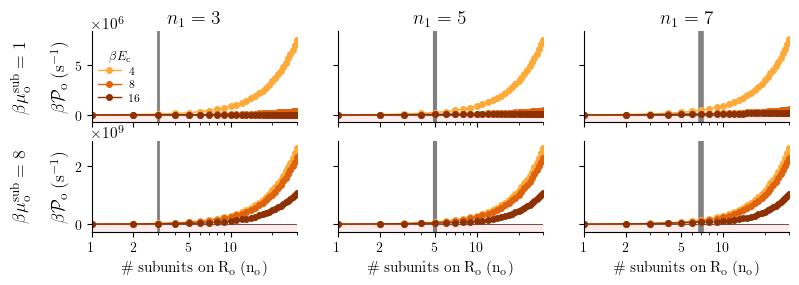

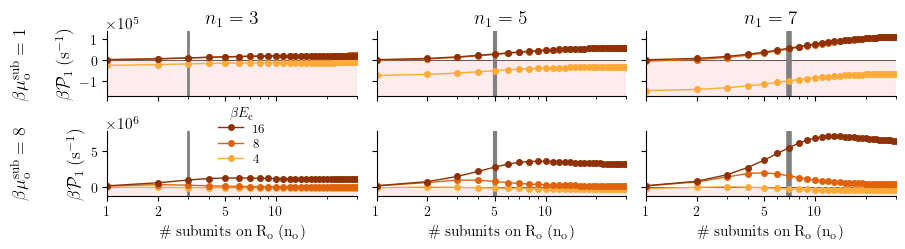

<Figure size 640x480 with 0 Axes>

In [238]:
def plot_figure4(target_dir, model, n0_array, Ec_curve, n1_array, f0_array, drag=1000):
    timescale = 4.8e7
    W, M = len(f0_array), len(n1_array)

    fig, ax = plt.subplots(W, M, figsize=(3*M, 1.3*W), sharey="row", sharex=True)
    fig0, ax0 = plt.subplots(W, M, figsize=(3*M, 1.3*W), sharey="row", sharex=True)

    if W == 1 and M == 1:
        ax, ax0 = np.array([[ax]]), np.array([[ax0]])
    elif W == 1:
        ax, ax0 = ax[np.newaxis, :], ax0[np.newaxis, :]
    elif M == 1:
        ax, ax0 = ax[:, np.newaxis], ax0[:, np.newaxis]

    colors = cm.Purples(np.linspace(0.5, 1, len(Ec_curve)))[::-1]
    colors = cm.YlOrBr(np.linspace(0.45, 0.9, len(Ec_curve)))[::-1]
    input_file_name = "/" + model + "_flux_power_efficiency_E0_{0}_E1_{1}_psi0_{2}_psi1_{3}_n0_{4}_n1_{5}_phase_{6}_outfile.dat"

    row_y_min, row_y_max = [np.inf]*W, [-np.inf]*W
    row_y_min0, row_y_max0 = [np.inf]*W, [-np.inf]*W

    # =========================================================================
    # NUMERICAL P1 AND P0
    # =========================================================================

    for wi, f0 in enumerate(f0_array):
        for mi, n1 in enumerate(n1_array):
            for i, Ec in enumerate(Ec_curve):
                n0_exists, P1_at_Ec, P0_at_Ec = [], [], []

                for n0 in n0_array:
                    n0n1_str = str(int(n0)) + "_" + str(int(n1))
                    target = target_dir if isinstance(target_dir, str) else target_dir[wi]
                    target_dir_temp = os.path.join(target, n0n1_str)

                    [E0, __, E1, psi_0, psi_1, psi_0_n, psi_1_n, __, __, m0, m1, phase, beta, gamma, __] = set_params(
                        model, n0, n1, f0, E0=2.0, E1=2.0
                    )

                    fpath = target_dir_temp + input_file_name.format(
                        E0, E1, psi_0, psi_1, n0, n1, phase
                    )

                    if not os.path.exists(fpath):
                        continue

                    data = loadtxt(fpath, unpack=True, usecols=(0, 1, 2, 3, 4, 5, 6))
                    Ec_list, flux_X, flux_Y, power_X, power_Y, eff, eff_mod = data

                    if np.ndim(Ec_list) == 0:
                        Ec_list, power_X, power_Y = [Ec_list], [power_X], [power_Y]

                    for j in range(len(Ec_list)):
                        if np.isclose(Ec_list[j], Ec):
                            n0_exists.append(int(n0))
                            P1_at_Ec.append(-2*pi*power_Y[j])
                            P0_at_Ec.append(2*pi*power_X[j])

                if not n0_exists:
                    continue

                y1 = timescale*np.asarray(P1_at_Ec)
                y0 = timescale*np.asarray(P0_at_Ec)

                ax[wi, mi].plot(
                    n0_exists, y1,
                    marker="o", lw=1.0, markersize=4,
                    label=fr"${int(Ec)}$",
                    color=colors[i], zorder=-i
                )

                ax0[wi, mi].plot(
                    n0_exists, y0,
                    marker="o", lw=1.0, markersize=4,
                    label=fr"${int(Ec)}$",
                    color=colors[i], zorder=-i
                )

                row_y_min[wi] = min(row_y_min[wi], np.nanmin(y1))
                row_y_max[wi] = max(row_y_max[wi], np.nanmax(y1))
                row_y_min0[wi] = min(row_y_min0[wi], np.nanmin(y0))
                row_y_max0[wi] = max(row_y_max0[wi], np.nanmax(y0))

            # symmetry match
            ax[wi, mi].axvline(
                n1, color="gray", linestyle="solid",
                linewidth=mi + 2, zorder=-50
            )
            ax0[wi, mi].axvline(
                n1, color="gray", linestyle="solid",
                linewidth=mi + 2, zorder=-50
            )

            # formatting
            for a, ylabel in [
                (ax[wi, mi], r"$\beta \mathcal{P}_{1} \ (\rm{s}^{-1})$"),
                (ax0[wi, mi], r"$\beta \mathcal{P}_{\rm o} \ (\rm{s}^{-1})$")
            ]:
                a.axhline(0.0, color="black", lw=0.5, zorder=-100)
                a.ticklabel_format(style="sci", axis="y", scilimits=(0, 0))
                a.yaxis.offsetText.set_fontsize(11)
                a.set_xscale("log")
                a.set_xlim(1, 30)
                a.set_xticks([1, 2, 5, 10])
                a.get_xaxis().set_major_formatter(
                    matplotlib.ticker.ScalarFormatter()
                )
                a.spines["right"].set_visible(False)
                a.spines["top"].set_visible(False)
                a.tick_params(labelsize=10)

                if wi == 0:
                    a.set_title(fr"$n_1 = {int(n1)}$", fontsize=14)

                if wi == W-1:
                    a.set_xlabel(
                        r"$\# \ \mathrm{subunits \ on} \ \rm{R}_{\rm o} \ (n_{\rm o})$",
                        fontsize=11
                    )

                if mi == 0:
                    a.set_ylabel(ylabel, fontsize=13)
                    a.annotate(
                        fr"$\beta\mu_{{\rm o}}^{{\rm sub}} = {f0/8:g}$",
                        xy=(-0.35, 0.5),
                        xycoords="axes fraction",
                        fontsize=13,
                        ha="center",
                        va="center",
                        rotation=90
                    )

    # =========================================================================
    # LEGENDS
    # =========================================================================

    # P1: first subplot of second row, original order (16, 12, 8, 4)
    legend_row = 1 if W > 1 else 0

    ax[legend_row, 0].legend(
        prop={"size": 9},
        title=r"$\beta E_{\rm c}$",
        title_fontsize=10,
        frameon=False,
        labelspacing=0.3,
        bbox_to_anchor=(0.4, 0.3))

    # P0: first subplot of first row, reversed order (4, 8, 12, 16)
    handles0, labels0 = ax0[0, 0].get_legend_handles_labels()

    ax0[0, 0].legend(
        handles0[::-1],
        labels0[::-1],
        prop={"size": 8},
        title=r"$\beta E_{\rm c}$",
        title_fontsize=9,
        frameon=False,
        labelspacing=0.3,
        bbox_to_anchor=(0.29, 0.1))
    

    # =========================================================================
    # ROW-WISE Y LIMITS + NEGATIVE-POWER SHADING
    # =========================================================================

    for wi in range(W):
        if row_y_min[wi] < np.inf:
            yr = row_y_max[wi] - row_y_min[wi]
            y_lo, y_hi = row_y_min[wi] - 0.1*yr, row_y_max[wi] + 0.1*yr

            for mi in range(M):
                ax[wi, mi].set_ylim(y_lo, y_hi)
                if y_lo < 0:
                    ax[wi, mi].axhspan(
                        y_lo, 0,
                        color="lightcoral",
                        alpha=0.15,
                        zorder=-100
                    )

        if row_y_min0[wi] < np.inf:
            yr0 = row_y_max0[wi] - row_y_min0[wi]
            y_lo0, y_hi0 = row_y_min0[wi] - 0.1*yr0, row_y_max0[wi] + 0.1*yr0

            for mi in range(M):
                ax0[wi, mi].set_ylim(y_lo0, y_hi0)
                if y_lo0 < 0:
                    ax0[wi, mi].axhspan(
                        y_lo0, 0,
                        color="lightcoral",
                        alpha=0.15,
                        zorder=-100
                    )

    # =========================================================================
    # SAVE BOTH FIGURES
    # =========================================================================

    fig.tight_layout()
    fig.savefig(
        "/Users/sara/Desktop/research/BFM_paper/P1_vs_n0_grid_model_model4.pdf",
        bbox_inches="tight"
    )
    plt.figure(fig.number)
    plt.show()

    fig0.tight_layout()
    fig0.savefig(
        "/Users/sara/Desktop/research/BFM_paper/P0_vs_n0_grid_model_model4.pdf",
        bbox_inches="tight"
    )
    plt.figure(fig0.number)
    plt.show()


# =============================================================================
# CALL
# =============================================================================

n0_array_n0_change = [float(n) for n in range(1, 31)]
Ec_curve_n0_change = [16.0, 8.0, 4.0]

target_dir = "/Users/sara/Desktop/Figs_paper_2/model4/pfe/"

plot_figure4(
    target_dir=target_dir,
    model="model4",
    n0_array=n0_array_n0_change,
    Ec_curve=Ec_curve_n0_change,
    n1_array=[3.0, 5.0, 7.0],
    f0_array=[8.0, 64.0],
    drag=1000
)

# C-ring and S-ring

Ec=16.0 not found for n0=1.0, n1=3.0, f0=16.0
Ec=12.0 not found for n0=1.0, n1=5.0, f0=16.0
Ec=32.0 not found for n0=1.0, n1=7.0, f0=16.0
Ec=8.0 not found for n0=6.0, n1=7.0, f0=64.0
Ec=8.0 not found for n0=9.0, n1=7.0, f0=64.0


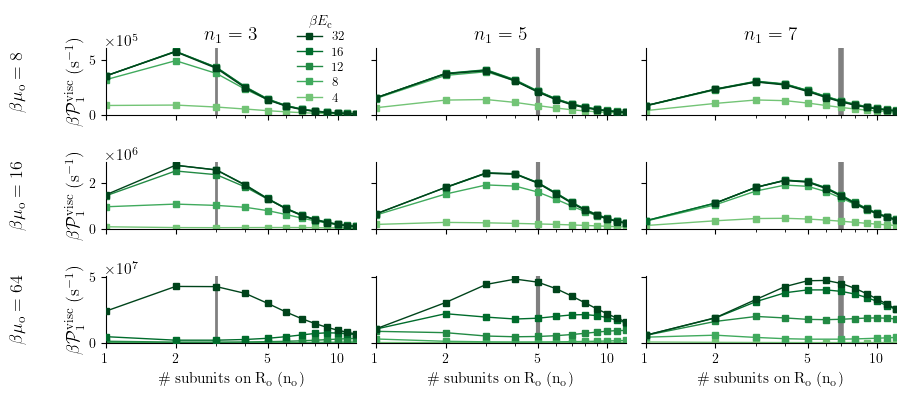

In [239]:
def plot_BFM_flux_vs_n0_grid(target_dir, n0_array, n1_array, Ec_array, f0_array, f1=0.0, gamma1=1500.0, dt=0.001, N=1000):
    model = "CS"
    timescale = 4.8e7

    W, M = len(f0_array), len(n1_array)
    fig, ax = plt.subplots(W, M, figsize=(3*M, 1.3*W), sharey="row", sharex=True)

    if W == 1 and M == 1:
        ax = np.array([[ax]])
    elif W == 1:
        ax = ax[np.newaxis, :]
    elif M == 1:
        ax = ax[:, np.newaxis]

    colors = cm.Greens(np.linspace(0.5, 1, len(Ec_array)))

    for row, f0 in enumerate(f0_array):
        for col, n1 in enumerate(n1_array):

            for jj, Ec in enumerate(Ec_array):
                n0_exists = []
                Pvisc_at_Ec = []

                for n0 in n0_array:
                    n0 = float(n0)
                    n1_temp = float(n1)
                    f0_temp = float(f0)
                    f1_temp = float(f1)
                    Ec_temp = float(Ec)

                    params = set_params(model, n0, n1_temp, f0_temp, f1_temp)
                    [E0, __, E1, psi_0, psi_1, psi_0_n, psi_1_n, __, __, m0, m1, phase, beta, gamma, __] = params

                    psi_1 = 0.0 if psi_1 == 0.0 else psi_1

                    n0n1_str = str(int(n0)) + "_" + str(int(n1_temp))
                    target_dir_temp = os.path.join(target_dir, n0n1_str)

                    input_file_name = model + "_flux_power_efficiency_E0_{0}_E1_{1}_psi0_{2}_psi1_{3}_n0_{4}_n1_{5}_phase_{6}_outfile.dat".format(float(E0), float(E1), float(psi_0), float(psi_1), float(n0), float(n1_temp), float(phase))
                    input_path = os.path.join(target_dir_temp, input_file_name)

                    if not os.path.exists(input_path):
                        print("MISSING:", input_path)
                        continue

                    Ec_list, integrate_flux_X, integrate_flux_Y, integrate_power_X, integrate_power_Y, efficiency, efficiency_mod = loadtxt(input_path, unpack=True, usecols=(0,1,2,3,4,5,6))

                    Ec_list = np.atleast_1d(Ec_list).astype(float)
                    integrate_flux_Y = np.atleast_1d(integrate_flux_Y)

                    matches = np.where(np.isclose(Ec_list, Ec_temp))[0]

                    if len(matches) == 0:
                        print(f"Ec={Ec_temp} not found for n0={n0}, n1={n1_temp}, f0={f0_temp}")
                        continue

                    j = matches[0]
                    J1 = integrate_flux_Y[j]

                    if np.isnan(J1):
                        continue

                    Pvisc = timescale*beta*gamma1*(2.0*np.pi*J1)**2

                    n0_exists.append(n0)
                    Pvisc_at_Ec.append(Pvisc)

                if len(n0_exists) == 0:
                    print(f"No usable data for f0={f0}, n1={n1}, Ec={Ec}")
                    continue

                n0_exists = np.array(n0_exists)
                Pvisc_at_Ec = np.array(Pvisc_at_Ec)

                # Higher Ec curves are drawn on top
                ax[row, col].plot(n0_exists, Pvisc_at_Ec, marker="s", markersize=4, lw=1.0, color=colors[jj], label=fr"${Ec:g}$", zorder=jj)

            # Symmetry match: same convention as Model 3
            ax[row, col].axvline(n1, color="gray", linestyle="solid", linewidth=col + 2, zorder=-50)

            ax[row, col].axhline(0.0, color="black", lw=0.5, zorder=-100)

            # Formatting
            ax[row, col].ticklabel_format(style="sci", axis="y", scilimits=(0, 0))
            ax[row, col].yaxis.offsetText.set_fontsize(11)
            ax[row, col].set_xscale("log")
            ax[row, col].set_xlim(1, 12)
            ax[row, col].set_xticks([1, 2, 5, 10])
            ax[row, col].get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
            ax[row, col].spines["right"].set_visible(False)
            ax[row, col].spines["top"].set_visible(False)
            ax[row, col].tick_params(labelsize=10)

            if row == 0:
                ax[row, col].set_title(fr"$n_1 = {int(n1)}$", fontsize=14)

            if row == W-1:
                ax[row, col].set_xlabel(r"$\# \ \mathrm{subunits \ on} \ \rm{R}_{\rm o} \ (n_{\rm o})$", fontsize=11)

            if col == 0:
                ax[row, col].set_ylabel(r"$\beta\mathcal{P}_1^{\rm visc} \ (\rm{s}^{-1})$", fontsize=13)
                ax[row, col].annotate(fr"$\beta\mu_{{\rm o}} = {int(f0)}$", xy=(-0.35, 0.5), xycoords="axes fraction", fontsize=13, ha="center", va="center", rotation=90)

            if row == 0 and col == 0:
                handles, labels = ax[row, col].get_legend_handles_labels()
                ax[row, col].legend(handles[::-1], labels[::-1], prop={"size": 9}, title=r"$\beta E_{\rm c}$", title_fontsize=10, frameon=False, labelspacing=0.3, loc="best")

    # Set zero as the bottom y-limit after all autoscaling is complete
    for row in range(W):
        ax[row, 0].set_ylim(bottom=0)

    fig.tight_layout()
    fig.savefig("/Users/sara/Desktop/Figs_paper_2/Pvisc_vs_n0_grid_model_CS.pdf", bbox_inches="tight")
    plt.show()


# =============================================================================
# PARAMETERS
# =============================================================================

target_dir = "/Users/sara/Desktop/BFM/CS_3_5_7/pfe/"

n0_array = np.arange(1.0, 13.0, 1.0)

# Columns
n1_array = [3.0, 5.0, 7.0]

# Rows
f0_array = [8.0, 16.0, 64.0]

# No direct downstream driving
f1 = 0.0

# Curves
Ec_array = [4.0, 8.0, 12.0, 16.0, 32.0]

gamma1 = 1500.0 

N = 1000
dt = 0.001


# =============================================================================
# PLOT
# =============================================================================

plot_BFM_flux_vs_n0_grid(target_dir=target_dir, n0_array=n0_array, n1_array=n1_array, Ec_array=Ec_array, f0_array=f0_array, f1=f1, gamma1=gamma1, dt=dt, N=N)